<a href="https://colab.research.google.com/github/joshalomskibest/SMARTRENT-NAIROBI/blob/main/SmartRent_Nairobi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries loaded successfully")

Libraries loaded successfully


In [4]:
np.random.seed(42)

In [5]:
df = pd.read_csv('/content/drive/MyDrive/SmartRent_Nairobi/Data/rent_apts_enriched (2).csv')

print(df.shape)
display(df.head())
df.info()

(1848, 11)


,Agency,Neighborhood,Price_Ksh,link,sq_mtrs,Bedrooms,Bathrooms,Building_Age_Years,Amenity_Count,Security_Level,Distance_to_CBD_km
0,Buy Rent Shelters,"General Mathenge, Westlands",155500,/listings/4-bedroom-apartment-for-rent-general...,4.0,4.0,4.0,12,6,Guard,7.4
1,Kenya Classic Homes,"Kilimani, Dagoretti North",96500,/listings/3-bedroom-apartment-for-rent-kiliman...,300.0,3.0,4.0,16,3,Gated+Guard+CCTV,8.9
2,Absolute Estate Agents,"Hatheru Rd,, Lavington, Dagoretti North",69000,/listings/3-bedroom-apartment-for-rent-lavingt...,3.0,3.0,5.0,13,3,NaN,6.5
3,A1 Properties Limited,"Kilimani, Dagoretti North",128000,/listings/3-bedroom-apartment-for-rent-kiliman...,227.0,3.0,4.0,9,1,Gated+Guard+CCTV,10.6
4,Pmc Estates Limited,"Imara Daima, Embakasi",38000,/listings/3-bedroom-apartment-for-rent-imara-d...,3.0,3.0,NaN,18,0,NaN,13.6


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1848 entries, 0 to 1847
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Agency              1848 non-null   object 
 1   Neighborhood        1848 non-null   object 
 2   Price_Ksh           1848 non-null   int64  
 3   link                1848 non-null   object 
 4   sq_mtrs             1846 non-null   float64
 5   Bedrooms            1845 non-null   float64
 6   Bathrooms           1557 non-null   float64
 7   Building_Age_Years  1848 non-null   int64  
 8   Amenity_Count       1848 non-null   int64  
 9   Security_Level      1454 non-null   object 
 10  Distance_to_CBD_km  1848 non-null   float64
dtypes: float64(4), int64(3), object(4)
memory usage: 158.9+ KB


In [6]:
df[['Bedrooms', 'sq_mtrs']].describe()


,Bedrooms,sq_mtrs
count,1845.000000,1846.000000
mean,2.577778,327.226977
std,0.819399,2048.784581
min,0.000000,0.000000
25%,2.000000,2.000000
50%,3.000000,3.000000
75%,3.000000,4.000000
max,6.000000,40470.000000


In [7]:
df[df['sq_mtrs'] < 15][['Bedrooms', 'sq_mtrs']].head(15)


,Bedrooms,sq_mtrs
0,4.0,4.0
2,3.0,3.0
4,3.0,3.0
5,2.0,2.0
6,2.0,14.0
8,4.0,4.0
9,2.0,2.0
10,2.0,2.0
11,3.0,3.0
12,3.0,3.0


In [8]:
df[df['sq_mtrs'] > 1000][['Bedrooms', 'sq_mtrs']]

,Bedrooms,sq_mtrs
48,1.0,2023.0
52,1.0,4000.0
57,1.0,1200.0
58,1.0,4000.0
66,1.0,4000.0
...,...,...
1730,1.0,2000.0
1731,2.0,20000.0
1758,3.0,4645.0
1766,3.0,2800.0


In [9]:
plausible_min = 15
plausible_max = 500

df['sq_mtrs_clean'] = df['sq_mtrs'].where(
    (df['sq_mtrs'] >= plausible_min) & (df['sq_mtrs'] <= plausible_max)
)

bedroom_medians = df.groupby('Bedrooms')['sq_mtrs_clean'].median()
print(bedroom_medians)

Bedrooms
0.0      NaN
1.0     90.0
2.0    120.0
3.0    181.0
4.0    232.0
5.0    270.0
6.0      NaN
Name: sq_mtrs_clean, dtype: float64


In [10]:
overall_median = df['sq_mtrs_clean'].median()
print("Overall fallback median:", overall_median)

df['sq_mtrs_filled'] = df['Bedrooms'].map(bedroom_medians)

df['sq_mtrs_filled'] = df['sq_mtrs_filled'].fillna(overall_median)

print("Missing before:", df['sq_mtrs'].isna().sum() + (df['sq_mtrs'] < plausible_min).sum() + (df['sq_mtrs'] > plausible_max).sum())
print("Missing after:", df['sq_mtrs_filled'].isna().sum())

Overall fallback median: 150.0
Missing before: 1526
Missing after: 0


In [11]:
df['sq_mtrs_final'] = df['sq_mtrs_clean'].fillna(df['Bedrooms'].map(bedroom_medians))
df['sq_mtrs_final'] = df['sq_mtrs_final'].fillna(overall_median)

changed = (df['sq_mtrs'] != df['sq_mtrs_final']).sum()
print("Rows changed:", changed)
print(df[['Bedrooms', 'sq_mtrs', 'sq_mtrs_final']].head(10))

Rows changed: 1526
   Bedrooms  sq_mtrs  sq_mtrs_final
0       4.0      4.0          232.0
1       3.0    300.0          300.0
2       3.0      3.0          181.0
3       3.0    227.0          227.0
4       3.0      3.0          181.0
5       2.0      2.0          120.0
6       2.0     14.0          120.0
7       3.0    186.0          186.0
8       4.0      4.0          232.0
9       2.0      2.0          120.0


In [12]:
df['sq_mtrs'] = df['sq_mtrs_final']
df = df.drop(columns=['sq_mtrs_clean', 'sq_mtrs_final'])

print(df['sq_mtrs'].describe())

count    1848.000000
mean      156.673160
std        50.210605
min        15.000000
25%       120.000000
50%       181.000000
75%       181.000000
max       418.000000
Name: sq_mtrs, dtype: float64


In [13]:
df[df['Bedrooms'].isna()]

,Agency,Neighborhood,Price_Ksh,link,sq_mtrs,Bedrooms,Bathrooms,Building_Age_Years,Amenity_Count,Security_Level,Distance_to_CBD_km,sq_mtrs_filled
69,Realty Plus,"Nairobi West, Langata",21500,/listings/studio-apartment-for-rent-nairobi-we...,150.0,NaN,NaN,5,0,NaN,7.4,150.0
121,Swiveltrend Ltd,"Ruaka, Kiambaa",30500,/listings/studio-apartment-for-rent-ruaka-1-34...,125.0,NaN,NaN,8,1,Guard,13.4,150.0
123,Realty Plus,"Nairobi West, Langata",32500,/listings/furnished-studio-apartment-for-rent-...,150.0,NaN,NaN,8,1,Guard,6.7,150.0


In [14]:
df.loc[df['Bedrooms'].isna(), 'Bedrooms'] = 0

print(df['Bedrooms'].isna().sum())

0


In [15]:
print(df.columns.tolist())

['Agency', 'Neighborhood', 'Price_Ksh', 'link', 'sq_mtrs', 'Bedrooms', 'Bathrooms', 'Building_Age_Years', 'Amenity_Count', 'Security_Level', 'Distance_to_CBD_km', 'sq_mtrs_filled']


In [16]:
df = df.drop(columns=['sq_mtrs_filled'])

# Confirm it's gone
print(df.columns.tolist())

['Agency', 'Neighborhood', 'Price_Ksh', 'link', 'sq_mtrs', 'Bedrooms', 'Bathrooms', 'Building_Age_Years', 'Amenity_Count', 'Security_Level', 'Distance_to_CBD_km']


In [17]:
df.groupby('Bedrooms')['Bathrooms'].median()

,Bathrooms
Bedrooms,
0.0,1.0
1.0,1.0
2.0,2.0
3.0,3.0
4.0,4.0
5.0,6.0
6.0,6.0


In [18]:
df['Bathrooms'].describe()

,Bathrooms
count,1557.000000
mean,2.595376
std,1.000349
min,1.000000
25%,2.000000
50%,2.000000
75%,3.000000
max,6.000000


In [19]:
# Step 1: Calculate median bathrooms per bedroom count (using existing valid data)
bathroom_medians = df.groupby('Bedrooms')['Bathrooms'].median()

# Step 2: Fill missing Bathrooms using each row's bedroom-group median
df['Bathrooms'] = df['Bathrooms'].fillna(df['Bedrooms'].map(bathroom_medians))

# Step 3: Confirm no missing values remain
print(df['Bathrooms'].isna().sum())

# Step 4: Sanity check the new distribution
print(df['Bathrooms'].describe())

0
count    1848.000000
mean        2.575216
std         0.979913
min         1.000000
25%         2.000000
50%         2.000000
75%         3.000000
max         6.000000
Name: Bathrooms, dtype: float64


In [20]:
df['Security_Level'].value_counts(dropna=False)

,count
Security_Level,
Guard,546
Gated+Guard,525
NaN,394
Gated+Guard+CCTV,383


In [21]:
df['Security_Level'] = df['Security_Level'].fillna('Unknown')

# Confirm no missing values remain
print(df['Security_Level'].isna().sum())

# See the final distribution including our new category
print(df['Security_Level'].value_counts())

0
Security_Level
Guard               546
Gated+Guard         525
Unknown             394
Gated+Guard+CCTV    383
Name: count, dtype: int64


In [22]:
df['Neighborhood'].nunique()
df['Neighborhood'].unique()

array(['General Mathenge, Westlands', 'Kilimani, Dagoretti North',
       'Hatheru Rd,, Lavington, Dagoretti North', 'Imara Daima, Embakasi',
       'Waiyaki Way, Westlands',
       'Off Denis Pritt, Kilimani, Dagoretti North',
       'Westlands Area, Westlands', 'Thika Road, Thika Road',
       'Raphta rd, Rhapta Road, Westlands', 'Thindigua, Thindigua',
       'Kileleshwa, Dagoretti North', 'Riverside, Westlands',
       'Riverside Drive, Riverside, Westlands', 'Parklands, Westlands',
       'Riara, Lavington, Dagoretti North',
       'nyali road, nyali road, Nyali Area, Nyali',
       'Sports Road, Waiyaki Way, Westlands', 'MUIRU, Ruaka, Kiambaa',
       'Ruaka, Kiambaa',
       'fisharies, mtambo bamburi road, Bamburi, Kisauni',
       'SHULE, Ruaka, Kiambaa',
       'Uthiru 87, Waiyaki Way, Uthiru/Ruthimitu, Dagoretti South',
       'Kiambu Road, Kiambu Road', 'Zimmerman, Zimmermann, Roysambu',
       'MUCHATHA- NATIONAL OIL, Ruaka, Kiambaa',
       'Kasarani Area, Kasarani',
    

In [23]:
non_nairobi_keywords = ['Nyali', 'Mombasa', 'Kisauni', 'Mvita', 'Bamburi', 'Mtwapa', 'Kilifi', 'Kisumu', 'Eldoret']
mask = df['Neighborhood'].str.contains('|'.join(non_nairobi_keywords), case=False, na=False)
print("Rows outside Nairobi metro:", mask.sum())
df[mask]['Neighborhood'].unique()

Rows outside Nairobi metro: 63


array(['nyali road, nyali road, Nyali Area, Nyali',
       'fisharies, mtambo bamburi road, Bamburi, Kisauni',
       'Bombolulu, Mombasa malindi road, Nyali Area, Nyali',
       'Shanzu serena, Serena, Nyali Area, Nyali',
       '50, 3rd avenue nyali, Nyali Area, Nyali',
       'links road, BEACH ROAD, Nyali Area, Nyali',
       'Kisumu Central Area, Kisumu Central',
       'Vok, New Malindi Mombasa road, Frere Town, Nyali',
       'Nyali Area, Nyali', 'links road, links road, Nyali Area, Nyali',
       'MOMBASA ROAD, Mombasa Road, Mombasa Road',
       'Links road, Links road, Ziwa La Ngombe, Nyali',
       'Nyali beach road, Nyali beach road, Nyali Area, Nyali',
       'Kisumu West, Kisumu West', 'mtwapa, Mtwapa, Kilifi South',
       'Mombasa Road, Mombasa Road',
       'Kisumu Road, Eldoret North, Eldoret North',
       'Beijing Road, Off Mombasa Road, Syokimau, Athi River',
       'Mamba village, Off links road, Nyali Area, Nyali',
       'Mkomani, Mkomani, Mkomani, Nyali',
     

In [24]:
# More precise: only flag genuinely non-Nairobi keywords, excluding "Mombasa Road" as a Nairobi-metro road
true_outlier_keywords = ['Nyali', 'Kisauni', 'Mvita', 'Bamburi', 'Mtwapa', 'Kilifi', 'Mombasa CBD', 'Kisumu', 'Eldoret']
mask = df['Neighborhood'].str.contains('|'.join(true_outlier_keywords), case=False, na=False)
print("Rows genuinely outside Nairobi metro:", mask.sum())

Rows genuinely outside Nairobi metro: 56


In [25]:
df['Neighborhood'].str.split(',').str[-1].str.strip().unique()


array(['Westlands', 'Dagoretti North', 'Embakasi', 'Thika Road',
       'Thindigua', 'Nyali', 'Kiambaa', 'Kisauni', 'Dagoretti South',
       'Kiambu Road', 'Roysambu', 'Kasarani', 'Kajiado North',
       'Athi River', 'Ngong', 'Kikuyu', 'Ruiru', 'Kisumu Central',
       'Kabete', 'Langata', 'Thika', 'Mombasa Road', 'Kisumu West',
       'Thika East', 'Kilifi South', 'Ngong Road', 'Kiambu Town',
       'Eldoret North', 'Kiambu Constituency', 'Starehe', 'Makadara',
       'Kangundo', 'Mombasa CBD', 'Milimani', 'Mvita', 'Muthaiga',
       'Ruaraka'], dtype=object)

In [26]:
true_outlier_keywords = ['Nyali', 'Kisauni', 'Mvita', 'Bamburi', 'Mtwapa', 'Kilifi', 'Mombasa CBD', 'Kisumu', 'Eldoret', 'Kangundo']
mask = df['Neighborhood'].str.contains('|'.join(true_outlier_keywords), case=False, na=False)
print("Final rows to drop:", mask.sum())

Final rows to drop: 58


In [27]:
# Drop rows outside Nairobi's metro area
df = df[~mask].reset_index(drop=True)

# Confirm the new shape
print(df.shape)

(1790, 11)


In [28]:
df['Neighborhood_clean'] = df['Neighborhood'].str.split(',').str[-2].str.strip()

print(df['Neighborhood_clean'].nunique())
df['Neighborhood_clean'].value_counts().head(20)

78


,count
Neighborhood_clean,
Kilimani,390
Kileleshwa,209
Lavington,195
Westlands Area,188
Riverside,109
Rhapta Road,82
Parklands,72
Ruaka,66
General Mathenge,52


In [29]:
import pandas as pd
pd.set_option('display.max_rows', None)
print(df['Neighborhood_clean'].value_counts())

Neighborhood_clean
Kilimani            390
Kileleshwa          209
Lavington           195
Westlands Area      188
Riverside           109
Rhapta Road          82
Parklands            72
Ruaka                66
General Mathenge     52
Brookside            44
Kiambu Road          39
Waiyaki Way          38
Riara Road           20
Ngong Road           19
Karen                17
Loresho              13
Valley Arcade        12
Syokimau             12
Upper Hill           11
Thindigua            11
Imara Daima          10
Thika Road           10
Naivasha Road         9
Spring Valley         8
Nairobi West          7
Runda                 7
Nyari                 7
Kahawa West           6
State House           6
Ngara                 5
Mountain View         5
Thigiri               5
Langata Area          5
Ngong                 5
Kikuyu Town           5
Mombasa Road          5
Madaraka              4
Hurlingham            4
Kasarani Area         4
Milimani              4
Karura               

In [30]:
neighborhood_counts = df['Neighborhood_clean'].value_counts()
frequent_neighborhoods = neighborhood_counts[neighborhood_counts >= 10].index

df['Neighborhood_final'] = df['Neighborhood_clean'].where(
    df['Neighborhood_clean'].isin(frequent_neighborhoods), 'Other'
)

print(df['Neighborhood_final'].value_counts())

Neighborhood_final
Kilimani            390
Kileleshwa          209
Lavington           195
Westlands Area      188
Other               171
Riverside           109
Rhapta Road          82
Parklands            72
Ruaka                66
General Mathenge     52
Brookside            44
Kiambu Road          39
Waiyaki Way          38
Riara Road           20
Ngong Road           19
Karen                17
Loresho              13
Valley Arcade        12
Syokimau             12
Thindigua            11
Upper Hill           11
Thika Road           10
Imara Daima          10
Name: count, dtype: int64


In [31]:
df = df.drop(columns=['Neighborhood', 'Neighborhood_clean', 'Area'], errors='ignore')
print(df.columns.tolist())

['Agency', 'Price_Ksh', 'link', 'sq_mtrs', 'Bedrooms', 'Bathrooms', 'Building_Age_Years', 'Amenity_Count', 'Security_Level', 'Distance_to_CBD_km', 'Neighborhood_final']


In [32]:
df[['Price_Ksh', 'Building_Age_Years', 'Distance_to_CBD_km']].describe()

,Price_Ksh,Building_Age_Years,Distance_to_CBD_km
count,1790.000000,1790.000000,1790.000000
mean,97162.011173,9.391061,8.003911
std,44914.010238,5.815510,4.943647
min,10500.000000,0.000000,2.700000
25%,63500.000000,5.000000,5.300000
50%,91500.000000,8.000000,6.600000
75%,129375.000000,13.000000,9.100000
max,278500.000000,33.000000,53.100000


In [33]:
df['Amenity_Count'].describe()

,Amenity_Count
count,1790.000000
mean,2.442458
std,1.796458
min,0.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,6.000000


In [34]:
df.nlargest(5, 'Distance_to_CBD_km')[['Neighborhood_final', 'Distance_to_CBD_km', 'Price_Ksh']]

,Neighborhood_final,Distance_to_CBD_km,Price_Ksh
157,Thika Road,53.1,32000
1550,Thika Road,47.8,126000
62,Other,47.4,17500
345,Other,42.5,42000
1753,Thika Road,40.7,134500


In [35]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1790 entries, 0 to 1789
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Agency              1790 non-null   object 
 1   Price_Ksh           1790 non-null   int64  
 2   link                1790 non-null   object 
 3   sq_mtrs             1790 non-null   float64
 4   Bedrooms            1790 non-null   float64
 5   Bathrooms           1790 non-null   float64
 6   Building_Age_Years  1790 non-null   int64  
 7   Amenity_Count       1790 non-null   int64  
 8   Security_Level      1790 non-null   object 
 9   Distance_to_CBD_km  1790 non-null   float64
 10  Neighborhood_final  1790 non-null   object 
dtypes: float64(4), int64(3), object(4)
memory usage: 154.0+ KB


,Price_Ksh,sq_mtrs,Bedrooms,Bathrooms,Building_Age_Years,Amenity_Count,Distance_to_CBD_km
count,1790.000000,1790.000000,1790.000000,1790.000000,1790.000000,1790.000000,1790.000000
mean,97162.011173,156.616760,2.577095,2.575419,9.391061,2.442458,8.003911
std,44914.010238,50.498527,0.826091,0.979191,5.815510,1.796458,4.943647
min,10500.000000,15.000000,0.000000,1.000000,0.000000,0.000000,2.700000
25%,63500.000000,120.000000,2.000000,2.000000,5.000000,1.000000,5.300000
50%,91500.000000,181.000000,3.000000,2.000000,8.000000,2.000000,6.600000
75%,129375.000000,181.000000,3.000000,3.000000,13.000000,4.000000,9.100000
max,278500.000000,418.000000,6.000000,6.000000,33.000000,6.000000,53.100000


In [36]:
df.to_csv('/content/drive/MyDrive/SmartRent_Nairobi/Data/rent_apts_cleaned.csv', index=False)

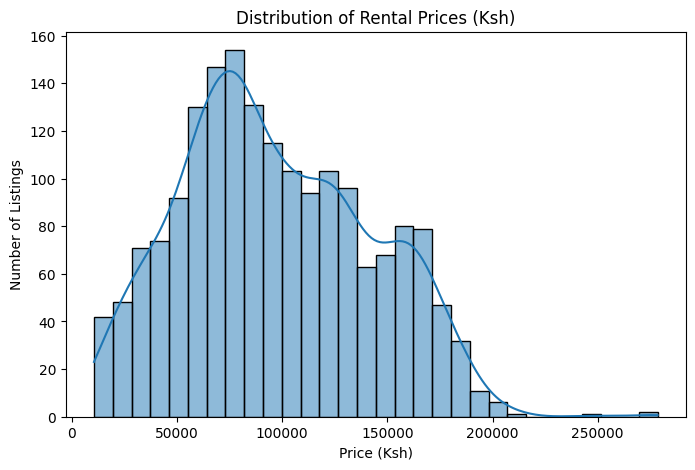

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price_Ksh'], bins=30, kde=True)
plt.title('Distribution of Rental Prices (Ksh)')
plt.xlabel('Price (Ksh)')
plt.ylabel('Number of Listings')
plt.show()

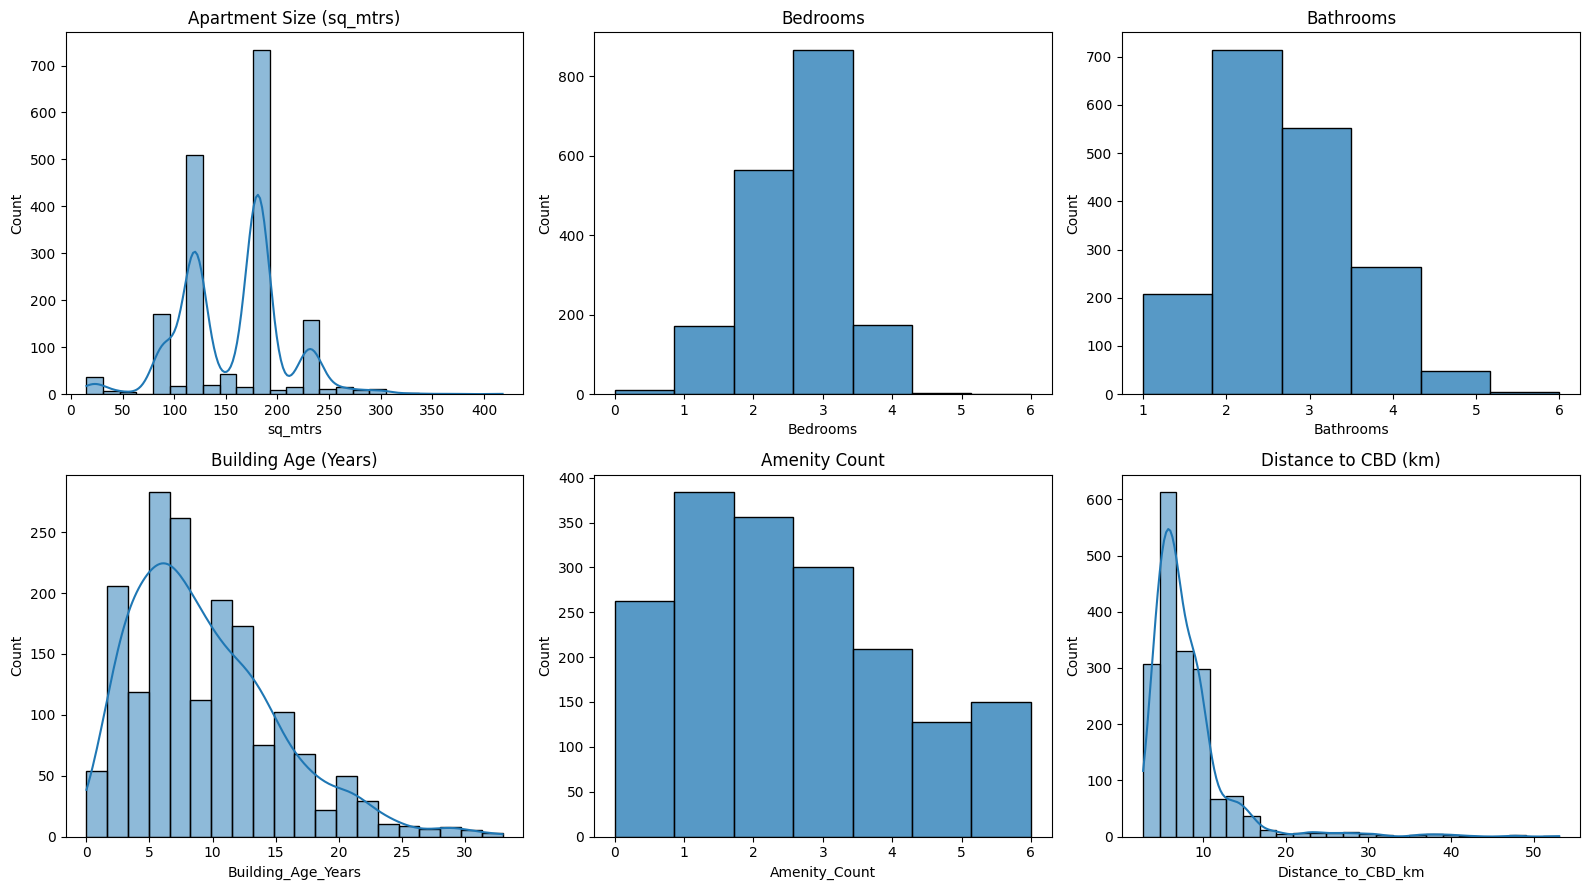

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.histplot(df['sq_mtrs'], bins=25, kde=True, ax=axes[0,0])
axes[0,0].set_title('Apartment Size (sq_mtrs)')

sns.histplot(df['Bedrooms'], bins=7, kde=False, ax=axes[0,1])
axes[0,1].set_title('Bedrooms')

sns.histplot(df['Bathrooms'], bins=6, kde=False, ax=axes[0,2])
axes[0,2].set_title('Bathrooms')

sns.histplot(df['Building_Age_Years'], bins=20, kde=True, ax=axes[1,0])
axes[1,0].set_title('Building Age (Years)')

sns.histplot(df['Amenity_Count'], bins=7, kde=False, ax=axes[1,1])
axes[1,1].set_title('Amenity Count')

sns.histplot(df['Distance_to_CBD_km'], bins=25, kde=True, ax=axes[1,2])
axes[1,2].set_title('Distance to CBD (km)')

plt.tight_layout()
plt.show()

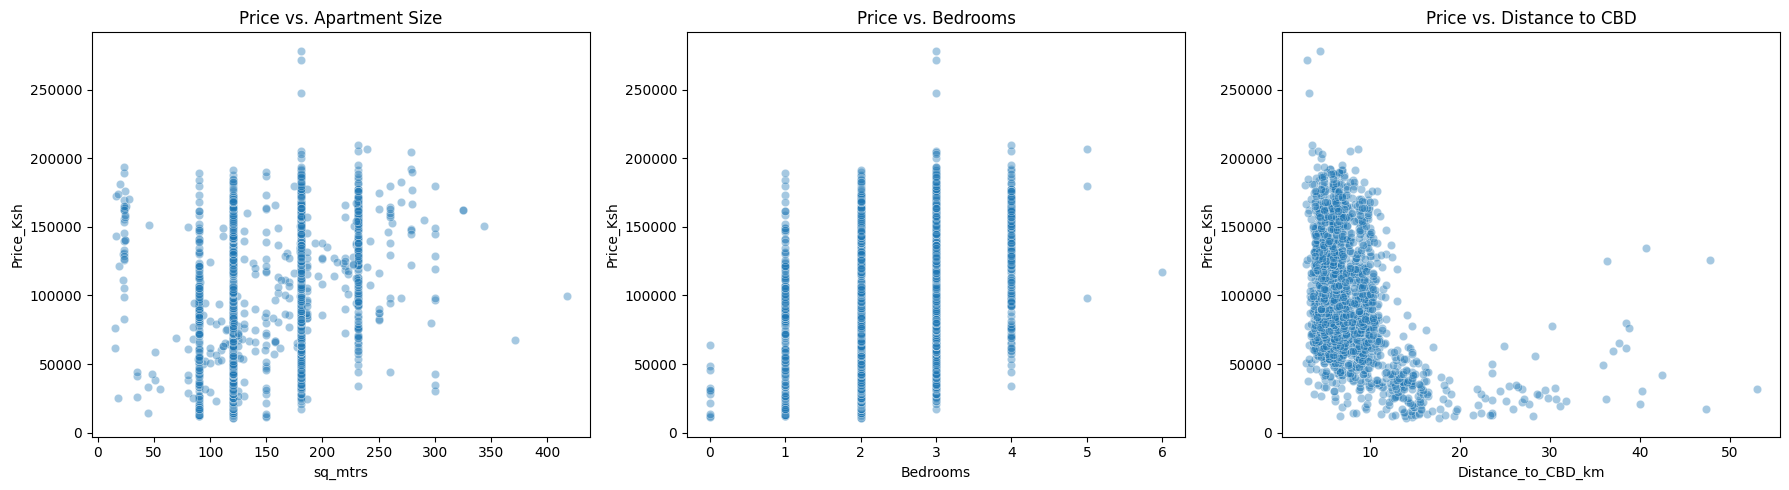

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='sq_mtrs', y='Price_Ksh', alpha=0.4, ax=axes[0])
axes[0].set_title('Price vs. Apartment Size')

sns.scatterplot(data=df, x='Bedrooms', y='Price_Ksh', alpha=0.4, ax=axes[1])
axes[1].set_title('Price vs. Bedrooms')

sns.scatterplot(data=df, x='Distance_to_CBD_km', y='Price_Ksh', alpha=0.4, ax=axes[2])
axes[2].set_title('Price vs. Distance to CBD')

plt.tight_layout()
plt.show()

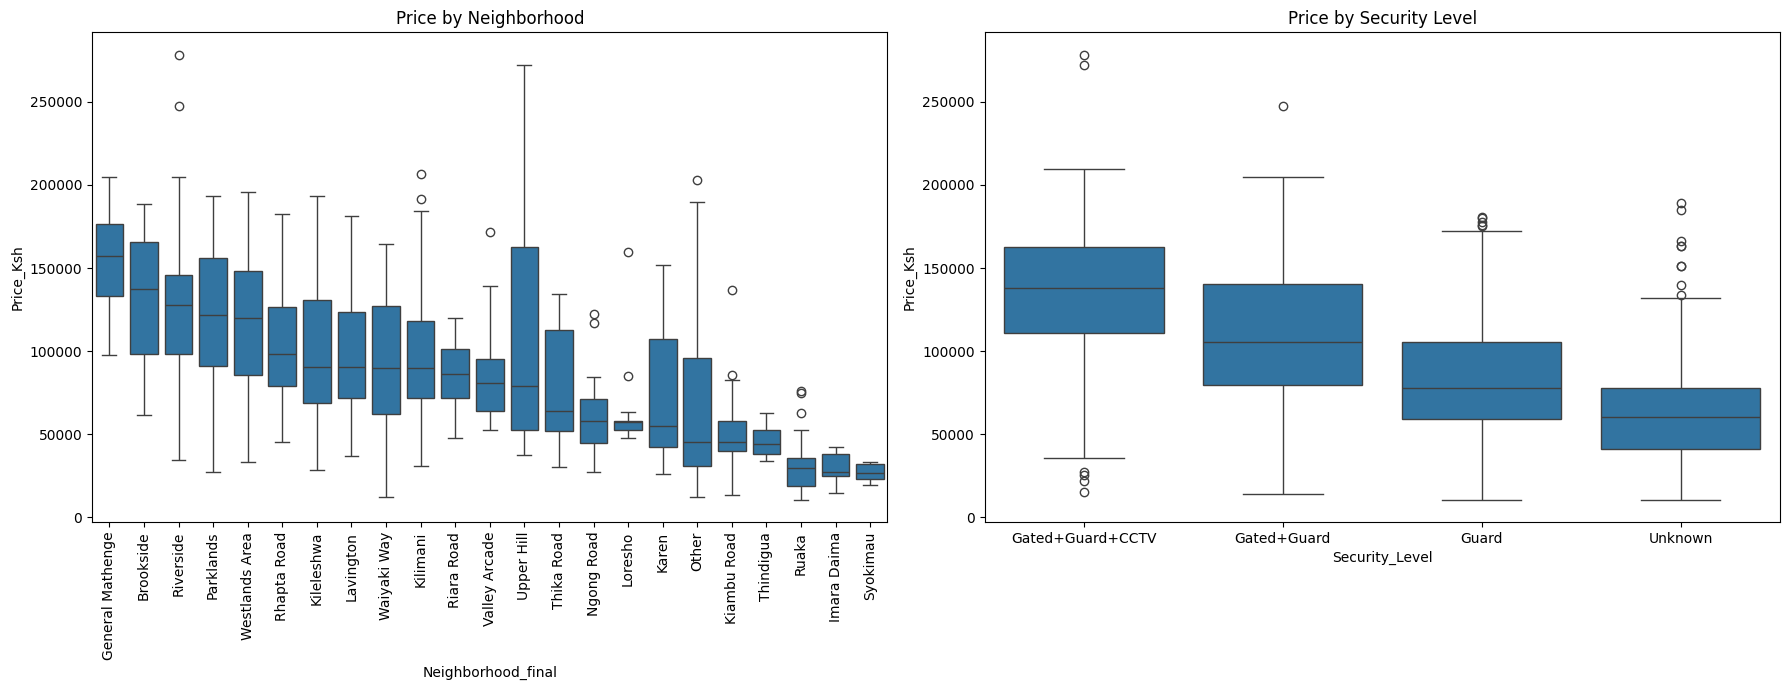

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

order1 = df.groupby('Neighborhood_final')['Price_Ksh'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Neighborhood_final', y='Price_Ksh', order=order1, ax=axes[0])
axes[0].set_title('Price by Neighborhood')
axes[0].tick_params(axis='x', rotation=90)

order2 = df.groupby('Security_Level')['Price_Ksh'].median().sort_values(ascending=False).index
sns.boxplot(data=df, x='Security_Level', y='Price_Ksh', order=order2, ax=axes[1])
axes[1].set_title('Price by Security Level')

plt.tight_layout()
plt.show()

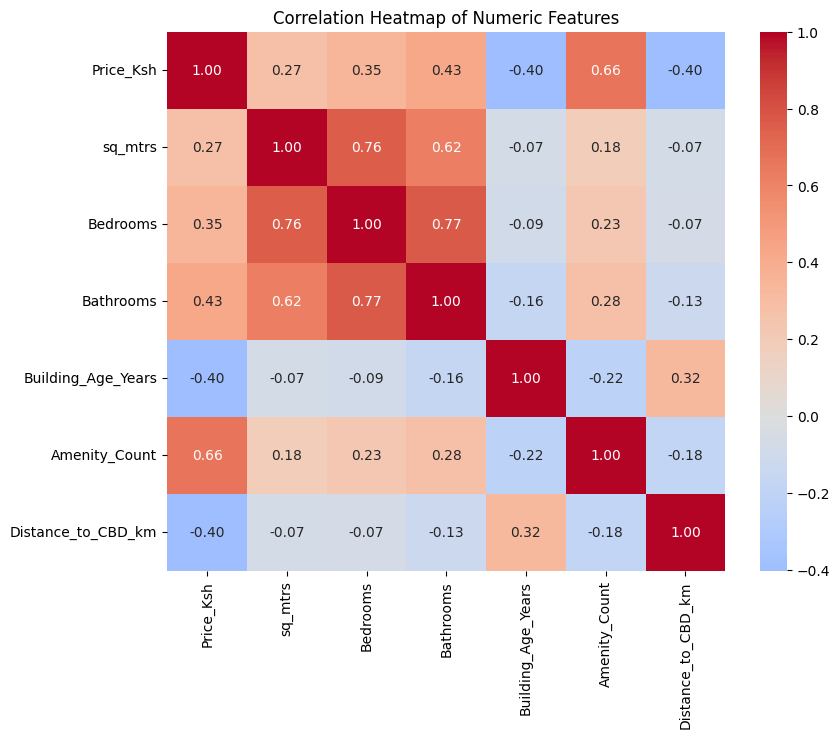

In [41]:
numeric_cols = ['Price_Ksh', 'sq_mtrs', 'Bedrooms', 'Bathrooms', 'Building_Age_Years', 'Amenity_Count', 'Distance_to_CBD_km']

plt.figure(figsize=(9,7))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

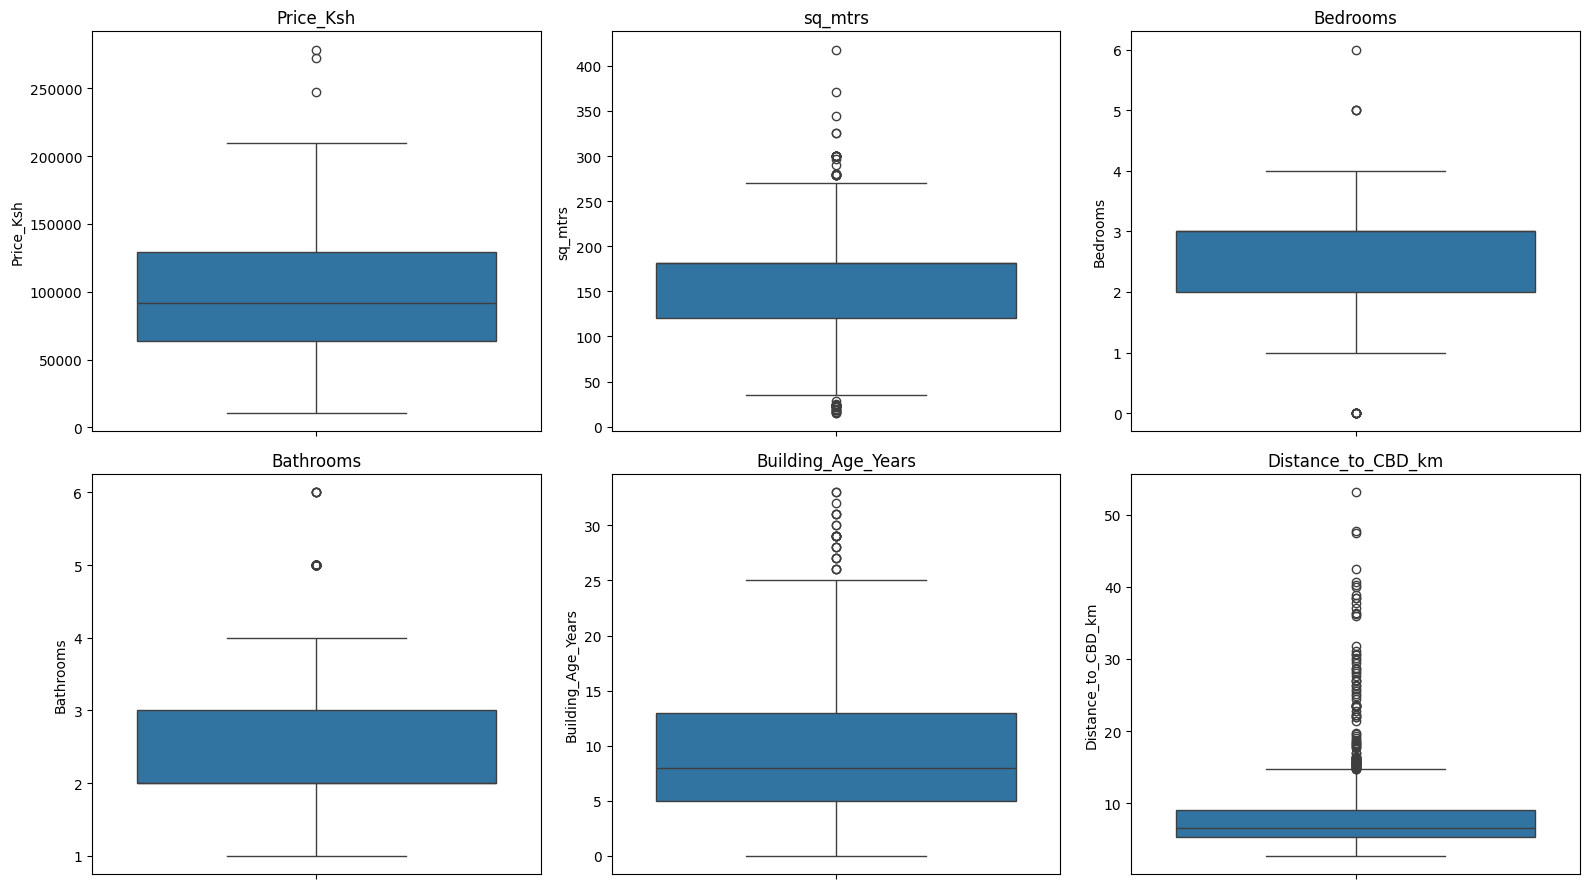

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.boxplot(y=df['Price_Ksh'], ax=axes[0,0])
axes[0,0].set_title('Price_Ksh')

sns.boxplot(y=df['sq_mtrs'], ax=axes[0,1])
axes[0,1].set_title('sq_mtrs')

sns.boxplot(y=df['Bedrooms'], ax=axes[0,2])
axes[0,2].set_title('Bedrooms')

sns.boxplot(y=df['Bathrooms'], ax=axes[1,0])
axes[1,0].set_title('Bathrooms')

sns.boxplot(y=df['Building_Age_Years'], ax=axes[1,1])
axes[1,1].set_title('Building_Age_Years')

sns.boxplot(y=df['Distance_to_CBD_km'], ax=axes[1,2])
axes[1,2].set_title('Distance_to_CBD_km')

plt.tight_layout()
plt.show()

In [43]:
y = df['Price_Ksh']
X = df.drop(columns=['Price_Ksh', 'Agency', 'link'])

X = pd.get_dummies(X, columns=['Neighborhood_final', 'Security_Level'], drop_first=True)

print(X.shape)
X.head()

(1790, 31)


,sq_mtrs,Bedrooms,Bathrooms,Building_Age_Years,Amenity_Count,Distance_to_CBD_km,Neighborhood_final_General Mathenge,Neighborhood_final_Imara Daima,Neighborhood_final_Karen,Neighborhood_final_Kiambu Road,...,Neighborhood_final_Syokimau,Neighborhood_final_Thika Road,Neighborhood_final_Thindigua,Neighborhood_final_Upper Hill,Neighborhood_final_Valley Arcade,Neighborhood_final_Waiyaki Way,Neighborhood_final_Westlands Area,Security_Level_Gated+Guard+CCTV,Security_Level_Guard,Security_Level_Unknown
0,232.0,4.0,4.0,12,6,7.4,True,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,300.0,3.0,4.0,16,3,8.9,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,181.0,3.0,5.0,13,3,6.5,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,227.0,3.0,4.0,9,1,10.6,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,181.0,3.0,3.0,18,0,13.6,False,True,False,False,...,False,False,False,False,False,False,False,False,False,True


In [44]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(1432, 31) (358, 31)


Linear Regression:

In [45]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, lr_pred)))
print("R²:", r2_score(y_test, lr_pred))

MAE: 18833.917997500146
RMSE: 24054.393278392345
R²: 0.7129100968434161


Random Forest default:

In [46]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R²:", r2_score(y_test, rf_pred))

MAE: 19133.095554003725
RMSE: 25195.02441262006
R²: 0.6850376288111553


Random Forest Tuned:

In [47]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.5, 1.0]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=30,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)
print("Best settings:", rf_search.best_params_)

best_rf = rf_search.best_estimator_
tuned_pred = best_rf.predict(X_test)

print("MAE:", mean_absolute_error(y_test, tuned_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, tuned_pred)))
print("R²:", r2_score(y_test, tuned_pred))

Best settings: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 10}
MAE: 18305.184388066373
RMSE: 24314.514864069515
R²: 0.7066674066733045


GB_Model:

In [48]:
gb_model = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

gb_pred = gb_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, gb_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, gb_pred)))
print("R²:", r2_score(y_test, gb_pred))

MAE: 17365.03716166576
RMSE: 22882.75665535866
R²: 0.7401960266825335


GB Tuned

In [49]:
param_dist_gb = {
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_leaf': [1, 2, 4, 8],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'max_features': ['sqrt', 0.5, 1.0]
}

gb_search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist_gb,
    n_iter=30,
    cv=5,
    scoring='neg_mean_absolute_error',
    random_state=42,
    n_jobs=-1
)

gb_search.fit(X_train, y_train)
print("Best settings:", gb_search.best_params_)

best_gb = gb_search.best_estimator_
tuned_gb_pred = best_gb.predict(X_test)

print("MAE:", mean_absolute_error(y_test, tuned_gb_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, tuned_gb_pred)))
print("R²:", r2_score(y_test, tuned_gb_pred))

Best settings: {'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 6, 'learning_rate': 0.01}
MAE: 17246.148373887376
RMSE: 22905.890751324412
R²: 0.7396704459306429


5-Fold Cross Validation

In [50]:
from sklearn.model_selection import cross_validate, KFold

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest (tuned)': best_rf,
    'Gradient Boosting (default)': gb_model,
    'Gradient Boosting (tuned)': best_gb
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    scores = cross_validate(model, X, y, cv=kf,
                            scoring=['neg_mean_absolute_error', 'r2'], n_jobs=-1)
    rows.append({
        'Model': name,
        'CV MAE': -scores['test_neg_mean_absolute_error'].mean(),
        'MAE std': scores['test_neg_mean_absolute_error'].std(),
        'CV R²': scores['test_r2'].mean(),
        'R² std': scores['test_r2'].std()
    })

pd.DataFrame(rows).round(3)

,Model,CV MAE,MAE std,CV R²,R² std
0,Linear Regression,18378.852,1253.523,0.715,0.023
1,Random Forest (tuned),17866.179,1231.892,0.719,0.026
2,Gradient Boosting (default),17686.099,995.514,0.727,0.024
3,Gradient Boosting (tuned),17115.452,1104.897,0.739,0.024


Feature Importance Chart

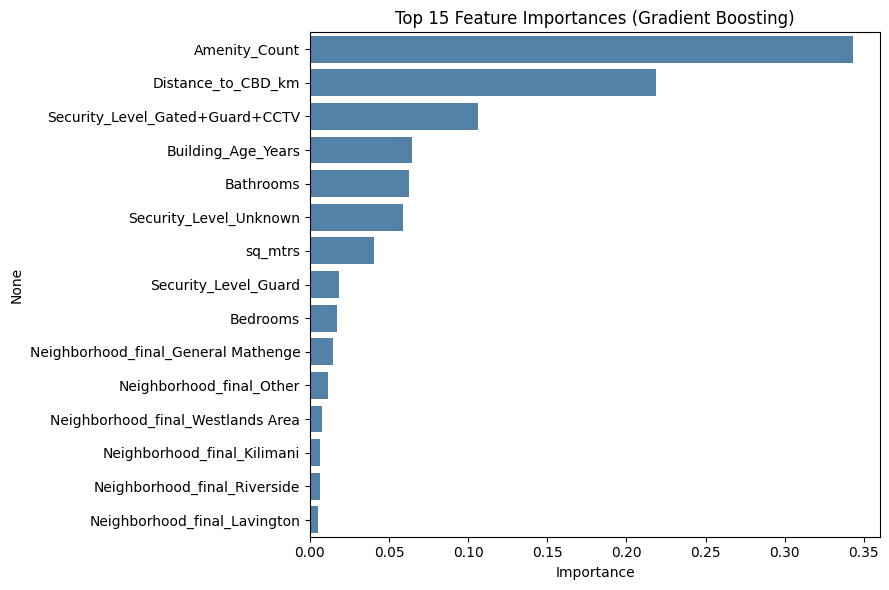

In [51]:
importances = pd.Series(best_gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top = importances.head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title('Top 15 Feature Importances (Gradient Boosting)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

In [52]:
groups = {
    'Neighborhood (all)': importances[importances.index.str.startswith('Neighborhood_final_')].sum(),
    'Security level (all)': importances[importances.index.str.startswith('Security_Level_')].sum(),
}
for col in ['Amenity_Count', 'Distance_to_CBD_km', 'Building_Age_Years', 'Bathrooms', 'sq_mtrs', 'Bedrooms']:
    groups[col] = importances[col]

pd.Series(groups).sort_values(ascending=False).round(3)

,0
Amenity_Count,0.343
Distance_to_CBD_km,0.219
Security level (all),0.183
Neighborhood (all),0.070
Building_Age_Years,0.064
Bathrooms,0.063
sq_mtrs,0.041
Bedrooms,0.017


In [53]:
import os
import joblib
import sklearn
from sklearn.base import clone

final_model = clone(best_gb)
final_model.fit(X, y)

save_dir = '/content/drive/MyDrive/SmartRent_Nairobi/Model/'
os.makedirs(save_dir, exist_ok=True)

joblib.dump(final_model, save_dir + 'smartrent_gb_model.joblib')
joblib.dump(list(X.columns), save_dir + 'model_columns.joblib')

print(os.listdir(save_dir))
print("scikit-learn version:", sklearn.__version__)

['model_columns.joblib', 'smartrent_gb_model.joblib']
scikit-learn version: 1.6.1
